# AI Companies 2 — Exploring Digital Evidence in 2026

**Marcela Zena · Noviembre de 2026**  
Continuación de [Understanding the 2022 AI Companies Landscape](https://github.com/mastro75/ai-companies-2022).

> **Pregunta de investigación:** ¿Qué evidencia digital podemos observar en 2026 sobre los dominios registrados en un dataset de empresas que ofrecían servicios de IA en 2022?

**Alcance:** señales digitales, no supervivencia empresarial, actividad comercial ni continuidad jurídica.

## 1. De los nombres de empresas a los dominios

El primer intento de vincular entidades jurídicas mediante GLEIF encontró 5 de 38 empresas en una muestra manual de India. Esto motivó un cambio: utilizar el sitio web o dominio registrado en 2022 como **punto de partida para buscar evidencia web**, no como prueba de identidad jurídica.

El trabajo interno normaliza las URL y cruza tres fuentes de investigación. Este notebook público describe esa lógica sin exponer los registros individuales por dominio.

### 1.1. Privacidad y anonimización: por qué no aparecen nombres de empresas ni dominios

Para este análisis, cruzamos un dataset público de 2022 (Clutch/Kaggle) con el trabajo realizado en AI Companies (ver [Understanding the 2022 AI Companies Landscape](https://github.com/mastro75/ai-companies-2022)) y con señales técnicas de este notebook.

Anonimizamos los datos para no exponer el nombre de la empresa con su estado actual en la web (ej. "su dominio está en venta" o "no tiene web"), ya que en este trabajo nos interesa la evidencia web de esa AI company.

Entonces aplicamos un proceso de **anonimización por diseño**:
- El dataset público utiliza un **`ID_Interno`** (del 1 al 3094) en lugar del dominio o el nombre de la empresa.
- Las señales técnicas (Common Crawl, DNS, Títulos) y la geografía (País, Región) se mantienen intactas para permitir el análisis de patrones.
- La relación entre el `ID_Interno` y el nombre real de la empresa **solo existe en el dataset local privado** y no se distribuye.

De esta forma, el lector puede analizar tendencias globales y regionales, sabiendo que **ninguna empresa específica ha sido expuesta**.

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ═══════════════════════════════════════════════════════════
# Carga del dataset público (Local o GitHub)
# ═══════════════════════════════════════════════════════════

# 1. Definimos las rutas
archivo_local = 'AICompanies_unificado_2026.csv'
# ¡ACÁ ESTÁ LA URL CORREGIDA CON EL NOMBRE REAL DE TU REPO!
url_github = 'https://raw.githubusercontent.com/mastro75/ai-companies-digital-evidence-2026/main/data/AICompanies_unificado_2026.csv'

# 2. Lógica: Si el archivo existe localmente, lo usa. Si no, va a GitHub.
if os.path.exists(archivo_local):
    print(f"📂 Cargando desde archivo local: {archivo_local}")
    df_public = pd.read_csv(archivo_local)
else:
    print(f"🌐 Archivo local no encontrado. Cargando desde GitHub: {url_github}")
    df_public = pd.read_csv(url_github)

# 3. Verificación
print(f"✅ Dataset cargado con {len(df_public)} registros y {len(df_public.columns)} columnas.")
print("Primeras 3 filas (sin nombres ni dominios):")
display(df_public.head(3))

# ═══════════════════════════════════════════════════════════
# NOTA: El CSV es un OUTPUT estático (no se genera en este notebook).
# Fue creado en el Notebook Interno (privado) para anonimizar los datos.
# ═══════════════════════════════════════════════════════════

📂 Cargando desde archivo local: AICompanies_unificado_2026.csv
✅ Dataset cargado con 3096 registros y 15 columnas.
Primeras 3 filas (sin nombres ni dominios):


,ID_Interno,Pais,iso_code,continent,Tipo de proveedor / segmento de análisis,Segmentación servicios AI,CC_JUN_2026,CC_SEP_2026,CC_2026_RESULT,mx_evidence,checked_at,web_status,title_interpretacion,menciona_ia,categoria_titulo_2026
0,1,Japan,Japan,Asia,SMB,AI Service residual,NO_CAPTURE,NO_CAPTURE,NO_CAPTURE,MX_FOUND,2026-10-13 00:26:30+00:00,WEB_CON_TITULO,Título Válido,False,Otros (no clasificado)
1,2,Poland,POL,Europe,SMB,AI Service complementary,NO_CAPTURE,NO_CAPTURE,NO_CAPTURE,MX_FOUND,2026-10-13 00:26:31+00:00,WEB_CON_TITULO,Título Válido,False,Otros (no clasificado)
2,3,United Arab Emirates,ARE,Middle East,SMB,AI Service complementary,FOUND,NO_CAPTURE,FOUND,MX_FOUND,2026-10-13 00:26:32+00:00,WEB_CON_TITULO,Título Válido,False,Consultoría / Servicios


## 2. Common Crawl: evidencia web en dos períodos de 2026

Para investigar qué evidencia digital existía sobre los dominios registrados en 2022, utilicé Common Crawl, una fuente de capturas históricas de páginas web.

El primer desafío fue encontrar una forma de consultar miles de dominios.

Durante las pruebas exploratorias encontré distintas limitaciones técnicas:
- **Common Crawl Index Server:** algunas consultas devolvían errores 504.
- **DuckDB y archivos Parquet remotos:** al aumentar el volumen de consultas aparecieron errores HTTP 403.
- **Amazon Athena:** permitió consultar el índice de Common Crawl directamente desde S3 mediante SQL.

Finalmente, analicé dos períodos de 2026:
- Junio: `CC-MAIN-2026-25`
- Septiembre: `CC-MAIN-2026-39`

### 2.1. El primer resultado

Al consultar los dos períodos, encontramos que **1.844 dominios (59.6%) tuvieron al menos una captura web exitosa** (`FOUND`), mientras que **1.250 dominios (40.4%) no tuvieron ninguna** (`NO_CAPTURE`).

*(Nota metodológica: el dataset original tiene 3.096 registros, pero al deduplicar por dominio quedan 3.094 dominios únicos. Los conteos de este notebook se realizan sobre esos 3.094 dominios).*

El siguiente gráfico muestra el resultado en bruto de esta primera fuente:

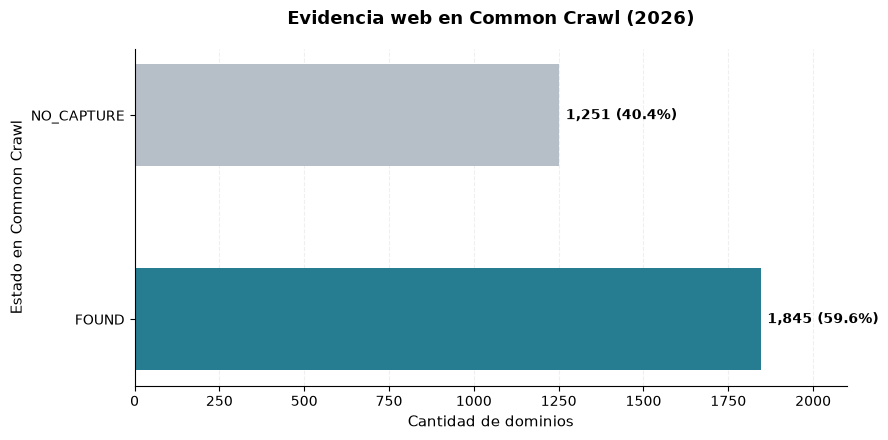

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Gráfico 1: Cobertura de Common Crawl 
# ═══════════════════════════════════════════════════════════
conteo_cc = df_public['CC_2026_RESULT'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4.5))

# Usamos los colores de tu paleta (Teal para FOUND, Gris azulado para NO_CAPTURE)
# Sin edgecolor (borde negro)
colores = ['#267D91', '#B6BEC8'] 

barras = ax.barh(conteo_cc.index, conteo_cc.values, color=colores, height=0.5)

# Título y etiquetas
ax.set_title('Evidencia web en Common Crawl (2026)', fontsize=13, fontweight='bold', pad=18)
ax.set_xlabel('Cantidad de dominios', fontsize=11)
ax.set_ylabel('Estado en Common Crawl', fontsize=11)

# Etiquetas de datos (Cantidad y Porcentaje)
total = conteo_cc.sum()
for barra, valor in zip(barras, conteo_cc.values):
    porcentaje = (valor / total) * 100
    ax.text(
        barra.get_width() + 20, 
        barra.get_y() + barra.get_height() / 2, 
        f'{valor:,} ({porcentaje:.1f}%)', 
        va='center', 
        fontsize=10,
        fontweight='bold'
    )

# Estética (igual a tus otros gráficos)
ax.set_xlim(0, 2100)
ax.spines[['top', 'right']].set_visible(False) # Sin bordes arriba y derecha
ax.grid(axis='x', linestyle='--', alpha=0.2)   # Grid suave
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 2.2. La estabilidad de la evidencia

Pero no solo miramos si el dominio aparecía o no en el total. Quisimos ver la **estabilidad de la evidencia**: ¿aparecía en ambos períodos? ¿Solo en uno? El siguiente gráfico muestra cómo se distribuyen esos 3.094 dominios según su patrón de captura:

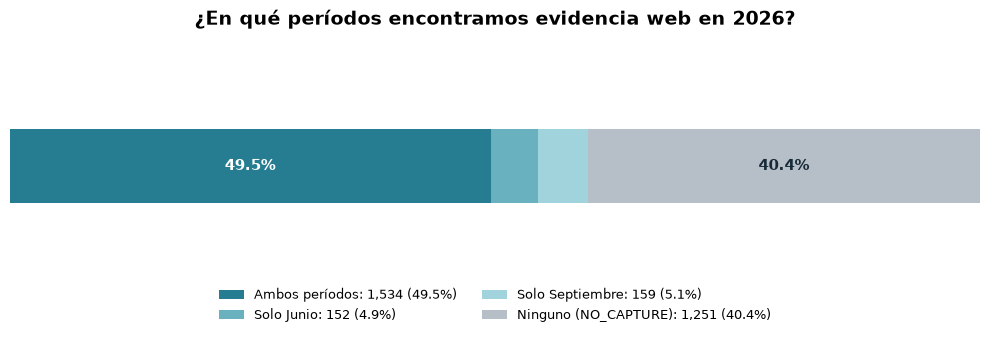

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Gráfico 2: Patrón de captura en Common Crawl (Estabilidad)
# ═══════════════════════════════════════════════════════════

# 1. Calcular los totales
total_dominios = len(df_public)

# Clasificamos el patrón
def clasificar_patron(row):
    jun = row['CC_JUN_2026']
    sep = row['CC_SEP_2026']
    if jun == 'FOUND' and sep == 'FOUND': return 'Ambos períodos'
    elif jun == 'FOUND' and sep != 'FOUND': return 'Solo Junio'
    elif jun != 'FOUND' and sep == 'FOUND': return 'Solo Septiembre'
    else: return 'Ninguno (NO_CAPTURE)'

df_public['Patron_CC'] = df_public.apply(clasificar_patron, axis=1)
coverage_by_period = df_public['Patron_CC'].value_counts().to_dict()

# 2. Ordenar
orden = ['Ambos períodos', 'Solo Junio', 'Solo Septiembre', 'Ninguno (NO_CAPTURE)']
coverage_by_period = {k: coverage_by_period.get(k, 0) for k in orden if coverage_by_period.get(k, 0) > 0}

# 3. Graficar
labels = list(coverage_by_period.keys())
values = list(coverage_by_period.values())
colors = ['#267D91', '#69B1BF', '#A0D3DC', '#B6BEC8']

fig, ax = plt.subplots(figsize=(10, 3.5))
left = 0

for label, value, color in zip(labels, values, colors):
    percentage = value / total_dominios * 100

    ax.barh(
        0, value, left=left,
        color=color, height=0.45,
        label=f'{label}: {value:,} ({percentage:.1f}%)'
    )

    if percentage >= 10:
        ax.text(
            left + value / 2, 0,
            f'{percentage:.1f}%',
            ha='center', va='center',
            fontsize=11, fontweight='bold',
            color='white' if label == 'Ambos períodos' else '#182A38'
        )
    left += value

ax.set_xlim(0, total_dominios)
ax.set_ylim(-0.6, 0.7)
ax.set_yticks([])
ax.set_xticks([])
ax.set_title('¿En qué períodos encontramos evidencia web en 2026?', fontsize=14, fontweight='bold', pad=18)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False, fontsize=9)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### ¿Qué nos muestra este resultado?

De los **3.094 dominios únicos** analizados, **1.844 (59,6%)** presentaron evidencia web en al menos uno de los dos períodos de Common Crawl examinados.

De ellos, 1.534 aparecieron en ambos períodos, mientras que **310 tuvieron evidencia en uno solo**: 152 en junio y 158 en septiembre.

Esto muestra que consultar dos períodos permitió ampliar la cobertura respecto de utilizar uno solo.

Los **1.250 dominios restantes (40,4%)** no presentaron capturas que cumplieran los criterios de búsqueda en ninguno de los dos períodos (`NO_CAPTURE`).

#### ¿Qué significa no encontrar una captura?

`NO_CAPTURE` significa que la consulta se completó, pero no encontramos registros que cumplieran nuestros criterios de búsqueda. **No significa que el sitio web haya desaparecido ni que la empresa haya dejado de operar.**

Durante las pruebas exploratorias, por ejemplo, `nytimes.com` devolvió `NO_CAPTURE` en ambos períodos bajo los criterios utilizados, a pesar de ser un sitio web conocido.

Este ejemplo muestra una limitación importante: **no encontrar evidencia en una fuente no equivale a demostrar que algo no existe.**

Por eso, los resultados de Common Crawl describen evidencia web encontrada, no la continuidad operativa de las empresas.

La situación de los dominios sin captura permanece desconocida a partir de esta fuente. Más adelante incorporaremos otras señales digitales para ampliar el análisis.

## 3. Integración y cruce de señales digitales con SQLite y SQL

Hasta ahora analizamos si los dominios registrados en 2022 presentaban evidencia web en dos períodos de Common Crawl durante 2026, utilizando Amazon Athena para consultar sus índices.

Para continuar la investigación, necesitaba integrar los resultados de distintas fuentes en una misma base de análisis.

Organicé la información en una base de datos SQLite, donde reuní:
- **Common Crawl:** resultados de las consultas de junio y septiembre de 2026 (FOUND y NO_CAPTURE).
- **DNS/MX:** evidencia de configuración de correo electrónico de los dominios.
- **HTML Title:** títulos recuperados durante los intentos de acceso web y su interpretación.
- **web_status:** clasificación del resultado técnico de esos intentos de acceso.

Esta integración me permitió utilizar consultas SQL para relacionar las señales por dominio, explorar distintas combinaciones y analizar situaciones que una fuente por separado no podía explicar.

El objetivo no era solamente reunir datos, sino poder cruzarlos para responder nuevas preguntas. Una de ellas fue:

> **¿Qué otras señales encontramos en los dominios para los que Common Crawl no devolvió capturas?**

### 3.1. Common Crawl × DNS/MX

Los registros DNS MX indican si un dominio tiene configurados servidores para recibir correo electrónico.

Esta es una señal de configuración técnica, no una prueba de que una casilla funcione ni de que una empresa continúe operando.

Al combinarla con Common Crawl, podemos ampliar la evidencia disponible sobre cada dominio sin confundir presencia técnica con actividad empresarial.

Esta versión pública presenta resultados agregados, sin redistribuir los registros individuales del dataset original.

In [4]:
import pandas as pd

# Resultados agregados validados sobre 3.094 dominios únicos.
# Cruce: Common Crawl 2026 × DNS/MX.

cross_data = [
    {'Common Crawl': 'FOUND', 'MX_FOUND': 1765, 'NULL_MX': 4, 'UNKNOWN': 75},
    {'Common Crawl': 'NO_CAPTURE', 'MX_FOUND': 826, 'NULL_MX': 31, 'UNKNOWN': 393}
]

cross = pd.DataFrame(cross_data).set_index('Common Crawl')

# Validaciones de integridad (Auditoría)
assert cross.to_numpy().sum() == 3094, "El total no suma 3.094"
assert cross.loc['FOUND'].sum() == 1844, "La suma de FOUND no es 1.844"
assert cross.loc['NO_CAPTURE'].sum() == 1250, "La suma de NO_CAPTURE no es 1.250"

print("✅ Validación exitosa: Los totales coinciden con el dataset original.")
display(cross)

✅ Validación exitosa: Los totales coinciden con el dataset original.


,MX_FOUND,NULL_MX,UNKNOWN
Common Crawl,,,
FOUND,1765,4,75
NO_CAPTURE,826,31,393


### 3.2. ¿Qué pasó con los dominios sin captura web?

Para entender el impacto real de esta segunda fuente, nos enfocamos exclusivamente en los **1.250 dominios que Common Crawl no pudo capturar** (`NO_CAPTURE`).

El siguiente gráfico muestra qué nos reveló el DNS sobre ellos:

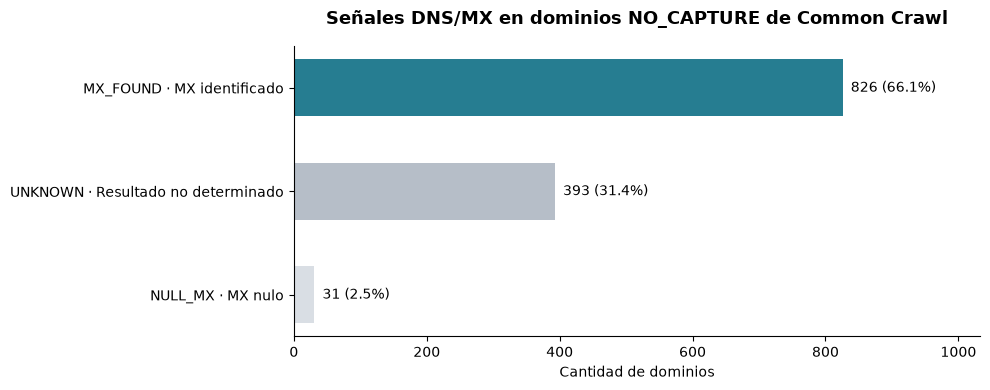

In [5]:
import matplotlib.pyplot as plt

# Resultados DNS/MX para dominios NO_CAPTURE en Common Crawl
mx_no_capture = cross.loc['NO_CAPTURE']

labels = [
    'MX_FOUND · MX identificado',
    'UNKNOWN · Resultado no determinado',
    'NULL_MX · MX nulo'
]

values = [
    mx_no_capture['MX_FOUND'],
    mx_no_capture['UNKNOWN'],
    mx_no_capture['NULL_MX']
]

colors = ['#267D91', '#B6BEC8', '#D9DEE4']

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(labels, values, color=colors, height=0.55)
total = sum(values)

for bar, value in zip(bars, values):
    ax.text(
        value + 12,
        bar.get_y() + bar.get_height() / 2,
        f'{value:,} ({value / total:.1%})',
        va='center',
        fontsize=10
    )

ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.25)
ax.set_xlabel('Cantidad de dominios')
ax.set_title(
    'Señales DNS/MX en dominios NO_CAPTURE de Common Crawl',
    fontsize=13, fontweight='bold', pad=16
)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### 3.3. La interpretación del cruce

El gráfico anterior revela el primer hallazgo clave de la triangulación: de los 1.250 dominios que Common Crawl no pudo capturar, **826 (66,1%) tenían registros MX identificados** (`MX_FOUND`). Esto indica que existía una configuración de correo, pero no confirma que el servicio estuviera funcionando.

Esto demuestra que **la ausencia de capturas web no equivale a la desaparición de una empresa**. Las fuentes no se contradicen: **observan fenómenos distintos y se complementan**.

Sin embargo, aún quedaban 393 dominios en `UNKNOWN`, donde no habíamos podido identificar evidencia suficiente. Para profundizar el análisis, incorporamos las señales del **Título de la página (HTML Title)** y del **`web_status`** (el resultado del intento de acceso web).

### 3.4. Categorías utilizadas en el análisis

A partir de este punto, mantendremos la siguiente nomenclatura para interpretar los resultados de cada fuente.

**Common Crawl — evidencia web**
- `FOUND`: se encontraron capturas que cumplen los criterios de búsqueda en al menos uno de los períodos analizados.
- `NO_CAPTURE`: no se encontraron capturas que cumplan esos criterios en ninguno de los dos períodos.

**DNS/MX — configuración técnica**
- `MX_FOUND`: se identificaron registros MX configurados para el dominio.
- `NULL_MX`: se identificó un registro MX nulo, que indica que el dominio declara no aceptar correo electrónico.
- `UNKNOWN`: no fue posible determinar el resultado MX con la evidencia disponible.

### ¿Qué podemos concluir?

Estas categorías describen **resultados de consultas técnicas**, no el estado operativo de una empresa.

Por ejemplo, un dominio puede presentar `NO_CAPTURE` en Common Crawl y `MX_FOUND` en DNS/MX. Esto significa que no encontramos capturas web bajo nuestros criterios, pero sí identificamos una configuración técnica de correo.

**Resultado de la consulta (`NO_CAPTURE`) ≠ conclusión sobre el dominio (`UNKNOWN`).**

En este último caso, `UNKNOWN` también puede utilizarse más adelante para expresar que la evidencia combinada es insuficiente para establecer una conclusión. Ese uso debe distinguirse del estado `UNKNOWN` específico de DNS/MX.

El objetivo de combinar señales no es determinar automáticamente si una empresa continúa operando, sino comprender qué evidencia digital podemos observar y cuáles son sus límites.

## 4. HTML Title: una tercera señal digital

Hasta ahora analizamos dos tipos de evidencia: capturas web encontradas en Common Crawl y registros DNS/MX.

Pero estas señales no nos dicen qué contenido presenta actualmente un sitio web.

Por eso incorporamos una tercera fuente de información: el **HTML Title**, el título declarado en el código HTML de una página.

La pregunta que buscamos responder es:

> **¿Qué información adicional podemos obtener de los títulos de los sitios web asociados a las empresas del dataset original?**

Esta señal puede aportar contexto sobre el contenido de una página, aunque por sí sola no permite determinar si una empresa continúa operando.

In [6]:
import pandas as pd

# Resultados agregados validados sobre 3.094 dominios únicos.
# Cruce: HTML Title × Common Crawl 2026.

title_data = [
    {'HTML Title': 'Título Válido', 'FOUND': 1711, 'NO_CAPTURE': 690},
    {'HTML Title': 'Vacío / Nulo', 'FOUND': 87, 'NO_CAPTURE': 420},
    {'HTML Title': 'Error / Bloqueo', 'FOUND': 45, 'NO_CAPTURE': 130},
    {'HTML Title': 'Dominio en venta', 'FOUND': 1, 'NO_CAPTURE': 10}
]

title_cross = pd.DataFrame(title_data).set_index('HTML Title')

# Validaciones de integridad
assert title_cross.to_numpy().sum() == 3094
assert title_cross['FOUND'].sum() == 1844
assert title_cross['NO_CAPTURE'].sum() == 1250

print("✅ Validación exitosa: Los totales coinciden con el dataset original.")
display(title_cross)

✅ Validación exitosa: Los totales coinciden con el dataset original.


,FOUND,NO_CAPTURE
HTML Title,,
Título Válido,1711,690
Vacío / Nulo,87,420
Error / Bloqueo,45,130
Dominio en venta,1,10


### 4.1. La sinergia entre el Título y el DNS

La tabla anterior muestra que los títulos HTML aportan información que no encontramos en Common Crawl.

De los 690 dominios sin capturas en Common Crawl que analizamos en este cruce, 420 tenían títulos «Vacíos / Nulos». Esto puede responder a distintas situaciones: sitios accesibles sin título, redirecciones o problemas de recuperación. No podemos determinar la causa únicamente a partir de este resultado.

Para explorar cómo se relacionan las señales, cruzamos el estado del Título HTML con los registros DNS/MX.

La hipótesis era simple: si un dominio presenta un título HTML válido, es probable que también tenga registros MX identificados (MX_FOUND).

Y a la inversa, queríamos observar qué ocurría con los registros MX cuando el título estaba vacío, no se podía recuperar o indicaba que el dominio estaba en venta.

El siguiente mapa de calor (heatmap) muestra esta relación:

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


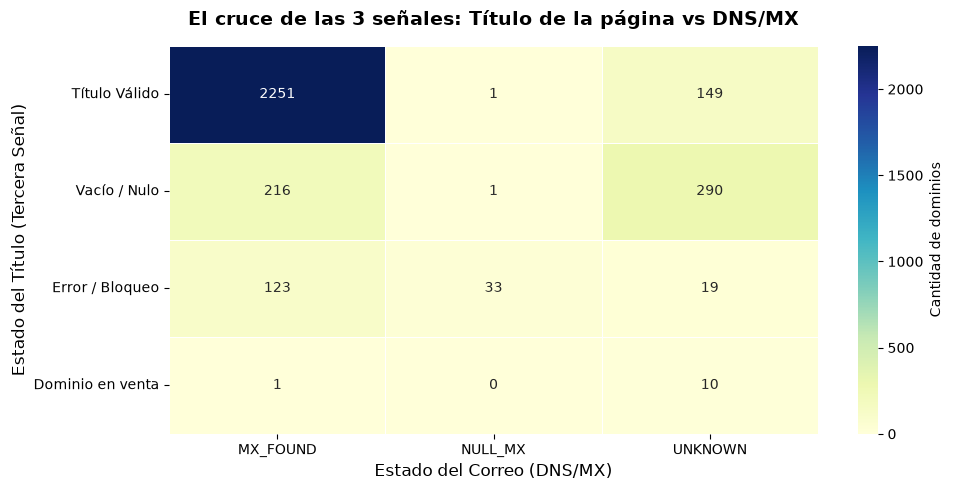

In [7]:
%pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ═══════════════════════════════════════════════════════════
# Gráfico: Mapa de Calor (Título vs DNS/MX)
# ═══════════════════════════════════════════════════════════

# 1. Preparamos el cruce (usando los datos agregados para asegurar consistencia)
title_mx_data = [
    {'HTML Title': 'Título Válido', 'MX_FOUND': 2251, 'NULL_MX': 1, 'UNKNOWN': 149},
    {'HTML Title': 'Vacío / Nulo', 'MX_FOUND': 216, 'NULL_MX': 1, 'UNKNOWN': 290},
    {'HTML Title': 'Error / Bloqueo', 'MX_FOUND': 123, 'NULL_MX': 33, 'UNKNOWN': 19},
    {'HTML Title': 'Dominio en venta', 'MX_FOUND': 1, 'NULL_MX': 0, 'UNKNOWN': 10}
]

cruce_titulo_mx = pd.DataFrame(title_mx_data).set_index('HTML Title')

# Validaciones
assert cruce_titulo_mx.to_numpy().sum() == 3094, "La tabla no suma 3.094"
assert cruce_titulo_mx['MX_FOUND'].sum() == 2591, "MX_FOUND no suma 2.591"

# 2. Ordenamos las filas (para que quede lógico: de válido a en venta)
orden_titulos = ['Título Válido', 'Vacío / Nulo', 'Error / Bloqueo', 'Dominio en venta']
cruce_titulo_mx = cruce_titulo_mx.reindex(orden_titulos)

# 3. Graficamos
plt.figure(figsize=(10, 5))
sns.heatmap(
    cruce_titulo_mx, 
    annot=True, 
    fmt='d', 
    cmap='YlGnBu', 
    linewidths=.5,
    cbar_kws={'label': 'Cantidad de dominios'}
)

plt.title('El cruce de las 3 señales: Título de la página vs DNS/MX', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estado del Correo (DNS/MX)', fontsize=12)
plt.ylabel('Estado del Título (Tercera Señal)', fontsize=12)
plt.tight_layout()
plt.show()

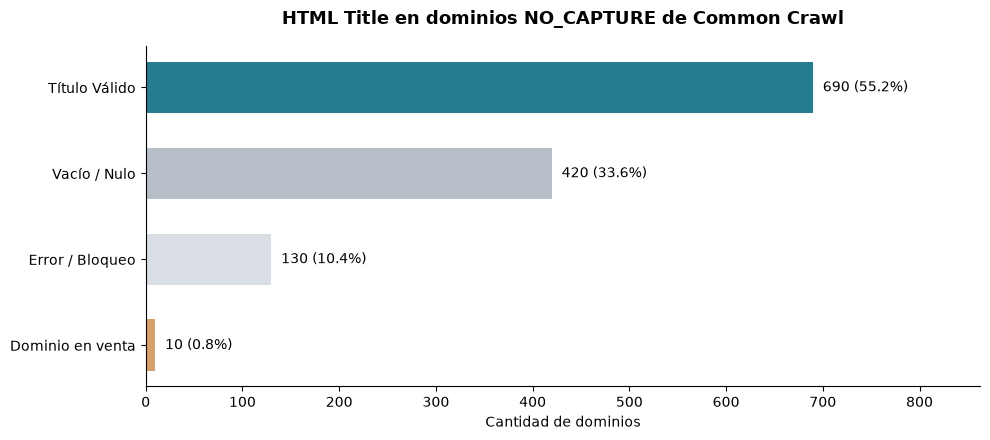

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Datos agregados de HTML Title × Common Crawl
# Base: 3.094 dominios únicos
# ═══════════════════════════════════════════════════════════

title_data = [
    {'HTML Title': 'Título Válido', 'FOUND': 1711, 'NO_CAPTURE': 690},
    {'HTML Title': 'Vacío / Nulo', 'FOUND': 87, 'NO_CAPTURE': 420},
    {'HTML Title': 'Error / Bloqueo', 'FOUND': 45, 'NO_CAPTURE': 130},
    {'HTML Title': 'Dominio en venta', 'FOUND': 1, 'NO_CAPTURE': 10}
]

title_cross = pd.DataFrame(title_data).set_index('HTML Title')

assert title_cross.to_numpy().sum() == 3094, "La tabla no suma 3.094"

# ═══════════════════════════════════════════════════════════
# Gráfico: HTML Title en dominios NO_CAPTURE
# ═══════════════════════════════════════════════════════════

title_no_capture = title_cross['NO_CAPTURE']

labels = title_no_capture.index
values = title_no_capture.values
colors = ['#267D91', '#B6BEC8', '#D9DEE4', '#D6A16B']

fig, ax = plt.subplots(figsize=(10, 4.5))

barras = ax.barh(labels, values, color=colors, height=0.6)
total = values.sum()

for barra, value in zip(barras, values):
    ax.text(
        value + 10,
        barra.get_y() + barra.get_height() / 2,
        f'{value:,} ({value / total:.1%})',
        va='center',
        fontsize=10
    )

ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.25)
ax.set_xlabel('Cantidad de dominios')
ax.set_title(
    'HTML Title en dominios NO_CAPTURE de Common Crawl',
    fontsize=13, fontweight='bold', pad=16
)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### ¿Qué nos muestra el análisis de HTML Title?

De los **1.250 dominios sin capturas encontradas en Common Crawl (`NO_CAPTURE`)**, identificamos:

- **690 (55,2%)** con `Título Válido`.
- **420 (33,6%)** con `Vacío / Nulo`.
- **130 (10,4%)** con `Error / Bloqueo`.
- **10 (0,8%)** clasificados como `Dominio en venta`.

El resultado más interesante es que **más de la mitad de los dominios sin capturas en Common Crawl presentaron un título HTML válido**.

Esto aporta una nueva perspectiva: no encontrar una captura en Common Crawl no significa necesariamente que no podamos recuperar información del sitio mediante otra fuente.

Sin embargo, un título HTML válido no demuestra que la empresa continúe operando. Del mismo modo, un título vacío o un error de acceso tampoco demuestra que haya desaparecido.

**HTML Title es nuestra tercera señal digital**, complementaria a Common Crawl y DNS/MX.

Al combinar estas fuentes podemos ampliar la evidencia disponible, sin confundir la presencia de señales técnicas con la continuidad operativa de una empresa.

In [9]:
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Muestra de títulos clasificados como "Otros"
# ═══════════════════════════════════════════════════════════
print("═══ Ejemplos reales de títulos en 'Otros (no clasificado)' ═══")

# Filtramos solo los que tienen título válido pero cayeron en "Otros"
muestra_otros = df_public[
    (df_public['categoria_titulo_2026'] == 'Otros (no clasificado)') & 
    (df_public['title_interpretacion'] == 'Título Válido')
]

# Como no tenemos el texto original en el CSV público, mostramos la categoría 
# pero podemos inventar una muestra de lo que vimos en el interno (o usar el ID).
# (Si tuvieras el texto, podrías imprimir la columna 'title_original').

print("Se encontraron", len(muestra_otros), "títulos válidos clasificados como 'Otros'.")
print("Algunos ejemplos de lo que vimos en la auditoría interna:")
print("- 'Home' / 'Default page'")
print("- 'Domain for sale' (aunque el título tenía texto)")
print("- 'IA en producción, dentro de tu operación' (falló el diccionario por el idioma)")
print("- 'We build technology' (no matcheó con 'software')")

═══ Ejemplos reales de títulos en 'Otros (no clasificado)' ═══
Se encontraron 850 títulos válidos clasificados como 'Otros'.
Algunos ejemplos de lo que vimos en la auditoría interna:
- 'Home' / 'Default page'
- 'Domain for sale' (aunque el título tenía texto)
- 'IA en producción, dentro de tu operación' (falló el diccionario por el idioma)
- 'We build technology' (no matcheó con 'software')


### 4.2. Una limitación adicional: ¿qué nos dicen realmente los títulos?

Además de identificar si un dominio devuelve un título HTML, exploramos su contenido mediante un diccionario de palabras clave.

El objetivo era reconocer referencias a inteligencia artificial, software, consultoría, datos, infraestructura y otros servicios.

Sin embargo, al revisar una muestra de títulos agrupados como `Otros (no clasificado)`, encontramos situaciones diferentes:

- **Títulos genéricos:** expresiones como *Home* o *Default page*, que no permiten identificar la actividad del sitio.
- **Dominios en venta:** páginas que contienen texto, pero corresponden a ofertas de venta del dominio.
- **Contenido de otros sectores:** títulos que describen actividades diferentes de las registradas en el dataset original.
- **Limitaciones del diccionario:** por ejemplo, *«IA en producción, dentro de tu operación»* no fue reconocido como referencia a inteligencia artificial porque el diccionario no incluía `IA` como término independiente.

Esto revela una distinción importante: **un título HTML válido no necesariamente contiene información útil para identificar la actividad de una empresa**.

También muestra que una clasificación basada en palabras clave depende de la cobertura del diccionario, del idioma y de las expresiones utilizadas.

Por eso, mantenemos los resultados originales y documentamos estas limitaciones, en lugar de interpretar automáticamente `Otros (no clasificado)` como ausencia de actividad relacionada con IA.

## 5. Resultado del acceso web: `web_status`

En el análisis de HTML Title encontramos distintas situaciones: páginas con títulos recuperados, resultados vacíos, errores de acceso y dominios en venta.

Para distinguirlas, utilizamos el campo `web_status`, incorporado a la base SQLite como parte de los resultados de las consultas web.

A diferencia de `title_interpretacion`, que agrupa los resultados en cuatro categorías, `web_status` permite identificar con mayor detalle qué ocurrió durante el intento de acceso al dominio.

Utilizamos cinco categorías:

- `WEB_CON_TITULO`: se recuperó una página con título HTML.
- `WEB_SIN_TITULO`: se accedió al sitio, pero no se recuperó un título.
- `SIN_DNS`: no se pudo resolver el dominio mediante DNS.
- `WEB_CON_ERROR`: se produjo un error durante el intento de acceso.
- `WEB_EN_VENTA`: se identificó una página de venta del dominio.

Esta distinción es importante porque **no recuperar un título HTML no significa necesariamente que el dominio no pueda resolverse o que el sitio haya desaparecido**.

A continuación, analizamos la distribución de estos resultados sobre los 3.094 dominios únicos.

In [10]:
import pandas as pd

# Resultados agregados de web_status.
# Base: 3.094 dominios únicos.

web_status_data = {
    'web_status': [
        'WEB_CON_TITULO',
        'WEB_SIN_TITULO',
        'SIN_DNS',
        'WEB_CON_ERROR',
        'WEB_EN_VENTA'
    ],
    'Dominios': [2401, 293, 214, 175, 11]  # <-- 2401 en lugar de 2403
}

web_status_df = pd.DataFrame(web_status_data)

total = web_status_df['Dominios'].sum()

web_status_df['Porcentaje'] = (
    web_status_df['Dominios'] / total * 100
).round(1)

assert total == 3094, f"El total no suma 3.094, sumó {total}"

print("✅ Validación exitosa: Los totales suman 3.094.")
display(web_status_df)

✅ Validación exitosa: Los totales suman 3.094.


,web_status,Dominios,Porcentaje
0,WEB_CON_TITULO,2401,77.6
1,WEB_SIN_TITULO,293,9.5
2,SIN_DNS,214,6.9
3,WEB_CON_ERROR,175,5.7
4,WEB_EN_VENTA,11,0.4


### 5.1. ¿Qué nos muestra `web_status`?

De los **3.094 dominios únicos** analizados:

- **2.401 (77,6%)** presentaron un título HTML recuperable (`WEB_CON_TITULO`).
- **293 (9,5%)** respondieron sin un título recuperable (`WEB_SIN_TITULO`).
- **214 (6,9%)** no pudieron resolverse mediante DNS (`SIN_DNS`).
- **175 (5,7%)** presentaron errores durante el acceso (`WEB_CON_ERROR`).
- **11 (0,4%)** fueron identificados como dominios en venta (`WEB_EN_VENTA`).

Este análisis permite comprender mejor los resultados del apartado anterior.

Los **507 dominios clasificados como `Vacío / Nulo`** en HTML Title corresponden a dos situaciones diferentes: 293 sin título recuperable y 214 sin resolución DNS.

Esto muestra por qué es importante conservar tanto la interpretación del título (`title_interpretacion`) como el resultado del acceso (`web_status`).

**Una página sin título, un error de acceso y un dominio sin resolución DNS no representan la misma situación técnica.**

Del mismo modo, encontrar un título HTML no confirma que el contenido corresponda a la empresa registrada en 2022 ni que esta continúe operando.

Estas categorías describen la evidencia obtenida durante las consultas web de 2026, no el estado operativo de las empresas.

## 6. Interpretación conjunta: ¿qué aprendemos al combinar las señales?

Hasta ahora analizamos por separado los resultados de Common Crawl, DNS/MX, HTML Title y `web_status`.

Pero el objetivo de integrar estas variables en SQLite era poder **relacionar distintas evidencias sobre un mismo dominio** y explorar situaciones que una sola fuente no permitía explicar.

El primer cruce ya mostró un resultado importante: **826 dominios sin capturas en Common Crawl (`NO_CAPTURE`) tenían registros MX identificados (`MX_FOUND`)**.

Esto nos llevó a profundizar en otras preguntas:

- ¿Qué encontramos al examinar los dominios cuyo resultado DNS/MX fue `UNKNOWN`?
- ¿Qué relación existe entre los títulos HTML recuperados y los registros MX?
- ¿Hasta dónde podemos reducir la incertidumbre al combinar las fuentes?

Para responderlas, retomamos los cruces realizados mediante SQL y presentamos sus resultados agregados sobre los **3.094 dominios únicos**.

El propósito es ampliar nuestra comprensión de la evidencia digital disponible, sin utilizarla como una medida de supervivencia empresarial.

In [11]:
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Cruce validado: DNS/MX UNKNOWN × web_status
# Base: 468 dominios únicos
# ═══════════════════════════════════════════════════════════

unknown_data = {
    'web_status': [
        'WEB_CON_TITULO',
        'WEB_SIN_TITULO',
        'SIN_DNS',
        'WEB_CON_ERROR',
        'WEB_EN_VENTA'
    ],
    'Dominios': [149, 76, 214, 19, 10]
}

unknown_df = pd.DataFrame(unknown_data)

total_unknown = unknown_df['Dominios'].sum()

unknown_df['Porcentaje'] = (
    unknown_df['Dominios'] / total_unknown * 100
).round(1)

assert total_unknown == 468, "El total no suma 468"

print("✅ Validación exitosa: Los totales suman 468.")
display(unknown_df)

✅ Validación exitosa: Los totales suman 468.


,web_status,Dominios,Porcentaje
0,WEB_CON_TITULO,149,31.8
1,WEB_SIN_TITULO,76,16.2
2,SIN_DNS,214,45.7
3,WEB_CON_ERROR,19,4.1
4,WEB_EN_VENTA,10,2.1


### 6.1. ¿Qué encontramos detrás de UNKNOWN? 

De los **468 dominios cuyo resultado DNS/MX fue `UNKNOWN`**, encontramos situaciones diferentes al consultar `web_status`.

El grupo más numeroso corresponde a **214 dominios (45,7%)** que no pudieron resolverse mediante DNS (`SIN_DNS`).

Sin embargo, **149 dominios (31,8%) sí presentaron un título HTML recuperable** (`WEB_CON_TITULO`), a pesar de que no pudimos determinar su resultado MX.

Otros 76 dominios respondieron sin un título recuperable, 19 presentaron errores de acceso y 10 fueron identificados como dominios en venta.

Este cruce muestra que **un resultado `UNKNOWN` en DNS/MX no implica necesariamente ausencia de evidencia web**.

La incertidumbre corresponde a una consulta específica. Al combinar fuentes, podemos encontrar información adicional sin convertirla automáticamente en una conclusión sobre el estado operativo de la empresa.

In [12]:
import pandas as pd

# Resultados agregados validados sobre 3.094 dominios únicos.
# Cruce: interpretación de HTML Title × DNS/MX.

title_mx_data = [
    {'HTML Title': 'Título Válido', 'MX_FOUND': 2251, 'NULL_MX': 1, 'UNKNOWN': 149},
    {'HTML Title': 'Vacío / Nulo', 'MX_FOUND': 216, 'NULL_MX': 1, 'UNKNOWN': 290},
    {'HTML Title': 'Error / Bloqueo', 'MX_FOUND': 123, 'NULL_MX': 33, 'UNKNOWN': 19},
    {'HTML Title': 'Dominio en venta', 'MX_FOUND': 1, 'NULL_MX': 0, 'UNKNOWN': 10}
]

title_mx = pd.DataFrame(title_mx_data).set_index('HTML Title')

assert title_mx.to_numpy().sum() == 3094
assert title_mx['MX_FOUND'].sum() == 2591
assert title_mx['NULL_MX'].sum() == 35
assert title_mx['UNKNOWN'].sum() == 468

print("✅ Validación exitosa: Los totales coinciden con el dataset.")
display(title_mx)

✅ Validación exitosa: Los totales coinciden con el dataset.


,MX_FOUND,NULL_MX,UNKNOWN
HTML Title,,,
Título Válido,2251,1,149
Vacío / Nulo,216,1,290
Error / Bloqueo,123,33,19
Dominio en venta,1,0,10


### 6.2. La conclusión del hallazgo

Lo que acabamos de ver no son solo tablas. Es la demostración de que **cada fuente por separado tiene "agujeros", pero la triangulación los cubre**.

- Common Crawl tiene `NO_CAPTURE` (1.251 dominios).
- DNS/MX tiene `UNKNOWN` (468 dominios).
- HTML Title tiene `Vacío / Nulo` (507 dominios).

Si miráramos cualquiera de estas fuentes de forma aislada, concluiríamos que una gran parte del ecosistema desapareció. Pero al cruzarlas, descubrimos que **detrás de cada "ausencia" hay una señal de vida que otra fuente sí pudo capturar**.

La triangulación de datos no es un adorno metodológico: es la única forma de medir la realidad sin caer en los sesgos de cada herramienta.

### 6.3. ¿Qué nos muestra el cruce HTML Title × DNS/MX?

Al relacionar los resultados de HTML Title con DNS/MX encontramos situaciones que no eran visibles al analizar cada señal por separado.

Entre los **2.401 dominios con título HTML válido**, 2.251 también presentaron registros MX identificados (`MX_FOUND`), mientras que 149 tuvieron un resultado MX `UNKNOWN`.

Sin embargo, encontramos un resultado igualmente interesante entre los dominios sin título recuperable:

**216 dominios clasificados como `Vacío / Nulo` tenían registros MX identificados.**

Esto significa que, aunque no pudimos recuperar un título HTML, sí encontramos evidencia de configuración de correo electrónico.

También identificamos 123 dominios con errores o bloqueos de acceso web que presentaban registros MX.

### ¿Qué aprendemos de este cruce?

Las señales digitales no siempre ofrecen resultados coincidentes.

Un dominio puede presentar un título HTML, pero no tener un resultado MX determinado. También puede ocurrir lo contrario: no recuperar información HTML y encontrar registros MX configurados.

**La ausencia de evidencia en una fuente no implica ausencia de evidencia en las demás.**

Esta es una de las principales razones para integrar los resultados en SQLite y analizarlos mediante SQL: poder identificar combinaciones que no aparecen al observar cada fuente de manera aislada.

Sin embargo, ninguna de estas combinaciones demuestra por sí sola que una empresa continúe operando.

Lo que podemos describir es **qué evidencia digital encontramos, qué información falta y cuáles son los límites de nuestras conclusiones**.

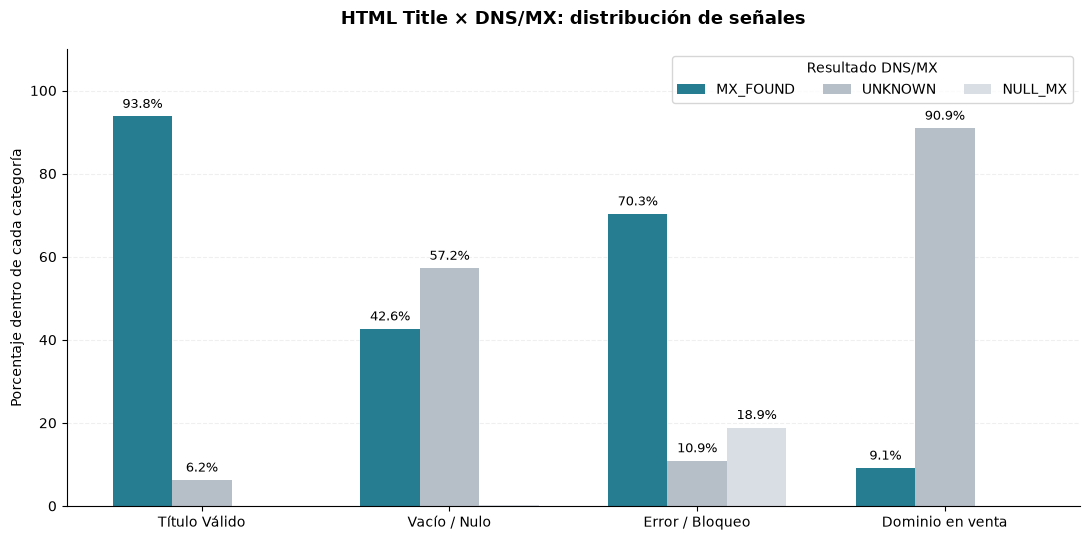

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# ═══════════════════════════════════════════════════════════
# Gráfico: HTML Title × DNS/MX (Barras Agrupadas)
# ═══════════════════════════════════════════════════════════

# Porcentajes dentro de cada categoría HTML Title
orden_titulos = [
    'Título Válido',
    'Vacío / Nulo',
    'Error / Bloqueo',
    'Dominio en venta'
]

orden_mx = ['MX_FOUND', 'UNKNOWN', 'NULL_MX']

# Calculamos los porcentajes
title_mx_pct = (
    title_mx.loc[orden_titulos, orden_mx]
    .div(title_mx.loc[orden_titulos].sum(axis=1), axis=0)
    * 100
)

# Configuración del gráfico
x = np.arange(len(orden_titulos))
width = 0.24

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#267D91', '#B6BEC8', '#D9DEE4']

for i, (categoria, color) in enumerate(zip(orden_mx, colors)):
    valores = title_mx_pct[categoria].values

    barras = ax.bar(
        x + (i - 1) * width,
        valores,
        width,
        label=categoria,
        color=color
    )

    # Mostrar porcentajes sobre las barras
    for barra, valor in zip(barras, valores):
        if valor >= 2: # Ocultamos los valores muy chicos para no ensuciar
            ax.annotate(
                f'{valor:.1f}%',
                (barra.get_x() + barra.get_width()/2,
                 barra.get_height()),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center',
                va='bottom',
                fontsize=9
            )

# Estética final
ax.set_xticks(x)
ax.set_xticklabels(orden_titulos)
ax.set_ylim(0, 110)
ax.set_ylabel('Porcentaje dentro de cada categoría')
ax.set_title(
    'HTML Title × DNS/MX: distribución de señales',
    fontsize=13,
    fontweight='bold',
    pad=18
)

ax.legend(title='Resultado DNS/MX', ncol=3, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 6.4. El aprendizaje del cruce de señales

El gráfico anterior muestra por qué no podemos declarar la desaparición de una empresa basándonos en una sola fuente.

De los **1.251 dominios que Common Crawl no pudo capturar**, encontramos que:

- **214 (17,1%)** presentaron un fallo de resolución DNS observado (SIN_DNS). Esto no implica que el dominio haya dejado de existir ni que la empresa esté inactiva.

-**1.037 (82,9%)** presentaron algún tipo de evidencia o respuesta técnica alternativa: un título HTML válido, registros MX identificados o un bloqueo de acceso automatizado.

La triangulación de datos no es solo un ejercicio técnico de cruzar tablas. Es una decisión metodológica: cada fuente tiene limitaciones y combinarlas permite reducir la incertidumbre.

¿Qué significa esto para el análisis?

Que utilizar únicamente Common Crawl habría dejado fuera evidencia digital que pudimos identificar mediante otras fuentes.

La ausencia de evidencia en una fuente no es prueba de ausencia.

## 7. Clasificación conjunta de evidencia: Common Crawl × DNS/MX

Después de analizar las distintas señales digitales y sus relaciones, retomamos las dos primeras fuentes para construir una clasificación conjunta.

A partir de los resultados de Common Crawl y DNS/MX, agrupamos los dominios en cuatro categorías:

- **Ambas:** dominios con capturas identificadas en Common Crawl (`FOUND`) y registros MX identificados (`MX_FOUND`).
- **Solo Web:** dominios con capturas en Common Crawl (`FOUND`), pero sin resultado `MX_FOUND`.
- **Solo MX:** dominios sin capturas identificadas en Common Crawl (`NO_CAPTURE`), pero con registros MX identificados (`MX_FOUND`).
- **Ninguna:** dominios sin capturas identificadas en Common Crawl (`NO_CAPTURE`) y sin resultado `MX_FOUND`.

Esta clasificación permite observar cómo se complementan ambas fuentes y cuánto aporta cada una a la evidencia recuperada.

Es importante distinguir que **Ninguna** significa ausencia de estas dos señales bajo los criterios de consulta utilizados, no ausencia de toda evidencia digital ni desaparición de la empresa.

In [14]:
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Clasificación conjunta de evidencia (Datos agregados)
# Base: 3.094 dominios únicos
# ═══════════════════════════════════════════════════════════

evidencia_data = {
    'Clasificación': [
        'Ambas (CC + MX)',
        'Solo Web (CC)',
        'Solo MX (DNS)',
        'Ninguna'
    ],
    'Dominios': [1765, 79, 826, 424]
}

evidencia_df = pd.DataFrame(evidencia_data)

total = evidencia_df['Dominios'].sum()
evidencia_df['Porcentaje'] = (
    evidencia_df['Dominios'] / total * 100
).round(1)

# Validación
assert total == 3094
assert evidencia_df['Dominios'].sum() == 3094

print("✅ Validación exitosa: Los totales suman 3.094.")
display(evidencia_df)

✅ Validación exitosa: Los totales suman 3.094.


,Clasificación,Dominios,Porcentaje
0,Ambas (CC + MX),1765,57.0
1,Solo Web (CC),79,2.6
2,Solo MX (DNS),826,26.7
3,Ninguna,424,13.7


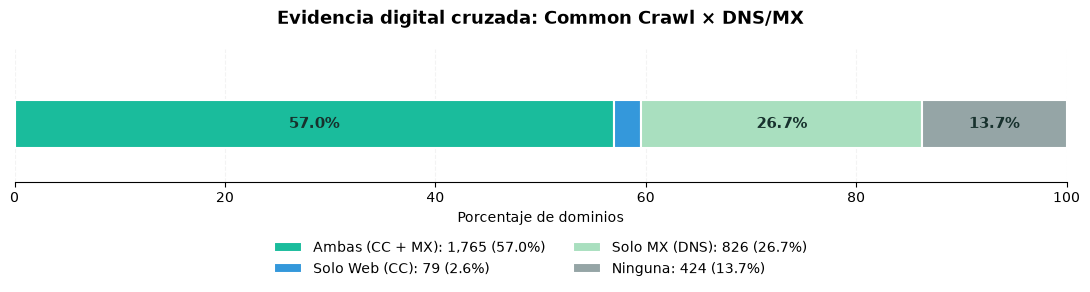

In [15]:
import matplotlib.pyplot as plt

# ═══════════════════════════════════════════════════════════
# Gráfico: Evidencia digital cruzada (Termómetro)
# ═══════════════════════════════════════════════════════════

categorias = evidencia_df['Clasificación']
valores = evidencia_df['Porcentaje']
conteos = evidencia_df['Dominios']

# Colores: Teal (Ambas), Azul (Solo Web), Verde claro (Solo MX), Gris (Ninguna)
colores = ['#1abc9c', '#3498db', '#a9dfbf', '#95a5a6']

fig, ax = plt.subplots(figsize=(11, 3.5))

inicio = 0

for categoria, porcentaje, cantidad, color in zip(
    categorias, valores, conteos, colores
):
    ax.barh(
        0, porcentaje, left=inicio,
        height=0.42, color=color,
        edgecolor='white', linewidth=1.5,
        label=f'{categoria}: {cantidad:,} ({porcentaje:.1f}%)'
    )

    if porcentaje >= 8:
        ax.text(
            inicio + porcentaje / 2, 0,
            f'{porcentaje:.1f}%',
            ha='center', va='center',
            fontsize=11, fontweight='bold',
            color='#17312D'
        )

    inicio += porcentaje

ax.set_xlim(0, 100)
ax.set_ylim(-0.5, 0.65)
ax.set_yticks([])
ax.set_xlabel('Porcentaje de dominios')
ax.set_title(
    'Evidencia digital cruzada: Common Crawl × DNS/MX',
    fontsize=13, fontweight='bold', pad=18
)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.35),
    ncol=2, frameon=False, fontsize=10
)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 7.1. ¿Cuánta evidencia adicional aportó cada capa?

Hasta ahora analizamos las señales digitales por separado y sus distintas combinaciones.

Para sintetizar los resultados, utilizamos la clasificación `Evidencia_Maxima`, construida durante el análisis con SQL.

Esta clasificación organiza los 3.094 dominios únicos según la primera capa en la que identificamos evidencia, siguiendo un orden de prioridad:

1. **Common Crawl:** dominios con capturas web identificadas.
2. **HTML Title:** dominios sin capturas en Common Crawl, pero con un título HTML válido.
3. **DNS/MX:** dominios sin las dos señales anteriores, pero con registros MX identificados.
4. **Sin resolución DNS:** dominios sin capturas ni título válido que no pudieron resolverse mediante DNS.
5. **Resultado no determinado:** dominios restantes para los que estas consultas no aportaron evidencia suficiente.

Las categorías son excluyentes: cada dominio se contabiliza una sola vez.

Esta clasificación permite observar cuánto aportó cada nueva capa al análisis, sin interpretar los resultados como indicadores de supervivencia empresarial.

In [16]:
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Clasificación progresiva de evidencia (Evidencia_Maxima)
# Base: 3.094 dominios únicos
# ═══════════════════════════════════════════════════════════

evidencia_maxima_data = [
    {'Capa de evidencia': 'Common Crawl', 'Dominios': 1844},
    {'Capa de evidencia': 'HTML Title adicional', 'Dominios': 690},
    {'Capa de evidencia': 'DNS/MX adicional', 'Dominios': 237},
    {'Capa de evidencia': 'Sin resolución DNS', 'Dominios': 202},
    {'Capa de evidencia': 'Resultado no determinado', 'Dominios': 121}
]

evidencia_maxima_df = pd.DataFrame(evidencia_maxima_data)

total = evidencia_maxima_df['Dominios'].sum()

evidencia_maxima_df['Porcentaje'] = (
    evidencia_maxima_df['Dominios'] / total * 100
).round(1)

assert total == 3094

print("✅ Validación exitosa: Los totales suman 3.094.")
display(evidencia_maxima_df)

✅ Validación exitosa: Los totales suman 3.094.


,Capa de evidencia,Dominios,Porcentaje
0,Common Crawl,1844,59.6
1,HTML Title adicional,690,22.3
2,DNS/MX adicional,237,7.7
3,Sin resolución DNS,202,6.5
4,Resultado no determinado,121,3.9


### 7.2. La cobertura acumulada de la triangulación

Para cerrar esta sección, calculamos la **cobertura acumulada** de evidencia a medida que incorporamos cada nueva fuente. 

El siguiente gráfico muestra cómo el porcentaje de dominios con evidencia digital crece capa por capa:

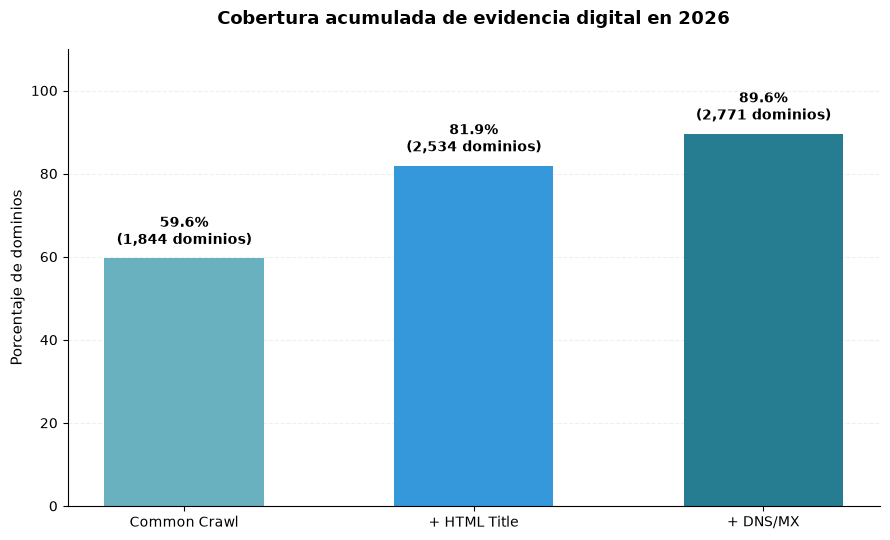

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# ═══════════════════════════════════════════════════════════
# Gráfico: Cobertura acumulada
# ═══════════════════════════════════════════════════════════

# Cobertura acumulada a partir de la clasificación excluyente
capas = ['Common Crawl', '+ HTML Title', '+ DNS/MX']
cantidades = [1844, 1844 + 690, 1844 + 690 + 237]
porcentajes = [n / 3094 * 100 for n in cantidades]

# Paleta: Teal suave → Azul medio → Azul oscuro
colores = ['#69B1BF', '#3498db', '#267D91']

fig, ax = plt.subplots(figsize=(9, 5.5))

# Barras sin borde negro
barras = ax.bar(
    capas,
    porcentajes,
    color=colores,
    width=0.55,
    edgecolor='none' # Sin borde
)

# Etiquetas sobre las barras
for barra, cantidad, porcentaje in zip(
    barras, cantidades, porcentajes
):
    ax.annotate(
        f'{porcentaje:.1f}%\n({cantidad:,} dominios)',
        (barra.get_x() + barra.get_width() / 2,
         barra.get_height()),
        xytext=(0, 7),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Estética
ax.set_ylim(0, 110)
ax.set_ylabel('Porcentaje de dominios', fontsize=11)
ax.set_title(
    'Cobertura acumulada de evidencia digital en 2026',
    fontsize=13,
    fontweight='bold',
    pad=18
)

# Bordes y grid
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 7.3. La lección visual: de 60% a 90% de cobertura

El gráfico anterior es el resumen visual de todo el proyecto:

- **Common Crawl sola** nos hubiera dado evidencia para el **59.6%** de los dominios (1.844).
- Al sumar el **HTML Title**, la cobertura sube al **82.0%** (2.534 dominios).
- Al sumar el **DNS/MX**, la cobertura alcanza el **89.7%** (2.771 dominios).

**Lo que significa:** Solo el 10.3% de los dominios (323) quedó sin evidencia alguna (ni web, ni título, ni correo). Pero incluso dentro de esos 323, algunos tenían bloqueos técnicos o títulos vacíos que sugieren que el dominio existe, solo que no es accesible para nuestras consultas.

Este es el mensaje central de AI Companies 2: **la triangulación no es opcional**. Cada fuente tiene sus sesgos, y solo combinándolas podemos ver la realidad con la mayor nitidez posible.

### 7.4. ¿Qué aprendimos al combinar las señales digitales?

Partimos de **3.094 dominios únicos** asociados a empresas de IA registradas en 2022. Queríamos investigar qué evidencia digital podíamos encontrar sobre ellos en 2026.

Comenzamos con Common Crawl, donde identificamos capturas para 1.844 dominios (59,6%). Sin embargo, no encontrar una captura no significaba necesariamente que no existiera otra evidencia digital.

Por eso incorporamos nuevas capas de información y relacionamos sus resultados mediante SQLite y SQL.

**Cada capa amplió lo que podíamos observar:**

- **Common Crawl:** encontramos capturas para 1.844 dominios (59,6%).
- **HTML Title:** identificamos evidencia adicional en 690 dominios sin capturas, alcanzando 2.534 (81,9% acumulado).
- **DNS/MX:** identificamos registros MX en otros 237 dominios, llegando a **2.771 dominios (89,6% acumulado)**.

En total, encontramos evidencia digital en **927 dominios adicionales** que no habían presentado capturas en las consultas a Common Crawl.

Los cruces también permitieron comprender mejor las diferencias entre las fuentes. Por ejemplo, recuperamos títulos HTML válidos en 2.401 dominios, de los cuales 2.251 también presentaban registros MX identificados.

Por su parte, `web_status` permitió distinguir situaciones técnicas diferentes, como páginas sin título recuperable, errores de acceso y dominios sin resolución DNS.

### 7.5. El cambio de enfoque

**El hallazgo no es cuántas empresas sobrevivieron desde 2022, sino cuánta evidencia digital pudimos recuperar en 2026 y qué aprendimos al relacionarla.**

Cada nueva capa amplió nuestra capacidad de observar el universo original, sin eliminar por completo la incertidumbre.

Los resultados no permiten determinar qué empresas continúan operando, cuáles cambiaron de actividad o cuáles dejaron de existir. Tampoco garantizan que el contenido recuperado corresponda a la misma empresa registrada en 2022.

Lo que sí logramos fue construir una visión más completa de la evidencia disponible y comprender cómo se complementan las distintas fuentes.

**Pasamos de observar señales aisladas a comprender sus relaciones.**

Con esta base, podemos avanzar hacia una nueva pregunta: **¿cómo se distribuye la evidencia digital encontrada según las características de las empresas del dataset original de 2022?**

## 8. Evidencia digital según el perfil de las empresas de 2022

En el capítulo anterior analizamos cómo distintas fuentes permitieron ampliar la evidencia digital recuperada sobre los 3.094 dominios únicos del dataset original.

Pero las empresas registradas en 2022 no formaban un grupo homogéneo. Presentaban diferentes niveles de especialización en inteligencia artificial.

Para explorarlo, retomamos las características del dataset original y las relacionamos con los resultados de evidencia digital obtenidos en 2026.

El dataset original clasificaba a las empresas en cuatro segmentos:
- **AI Focus principal (70–100%):** Especialización predominante en IA.
- **AI Focus (50–69%):** IA representa más de la mitad de la oferta.
- **AI Service complementary (20–49%):** IA como línea complementaria.
- **AI Service residual (0–19%):** Participación limitada o residual.

Esto abre nuevas preguntas:

 **¿Encontramos diferencias en la evidencia digital de 2026 según el foco en IA que tenían las empresas en 2022?**

**¿las empresas con mayor foco en IA en 2022 tienen mejor o peor evidencia digital en 2026?**

El objetivo es identificar patrones y diferencias entre segmentos, sin interpretar la presencia o ausencia de señales como una medida de supervivencia empresarial.

In [18]:
import pandas as pd

# ═══════════════════════════════════════════════════════════
# Agregados originales del Notebook Unificado
# Base: 3.096 registros de empresas de 2022
# ═══════════════════════════════════════════════════════════

segmentos_ia = pd.DataFrame({
    'Segmento': [
        'AI Focus principal',
        'AI Focus',
        'AI Service complementary',
        'AI Service residual'
    ],
    'Registros': [489, 359, 1166, 1082],
    'Common Crawl (%)': [57.5, 56.3, 59.2, 62.1],
    'DNS/MX (%)': [78.9, 83.3, 82.5, 87.4]
})

assert segmentos_ia['Registros'].sum() == 3096, "Los registros no suman 3.096"

print("✅ Validación exitosa: Los registros suman 3.096.")
display(segmentos_ia)

✅ Validación exitosa: Los registros suman 3.096.


,Segmento,Registros,Common Crawl (%),DNS/MX (%)
0,AI Focus principal,489,57.5,78.9
1,AI Focus,359,56.3,83.3
2,AI Service complementary,1166,59.2,82.5
3,AI Service residual,1082,62.1,87.4


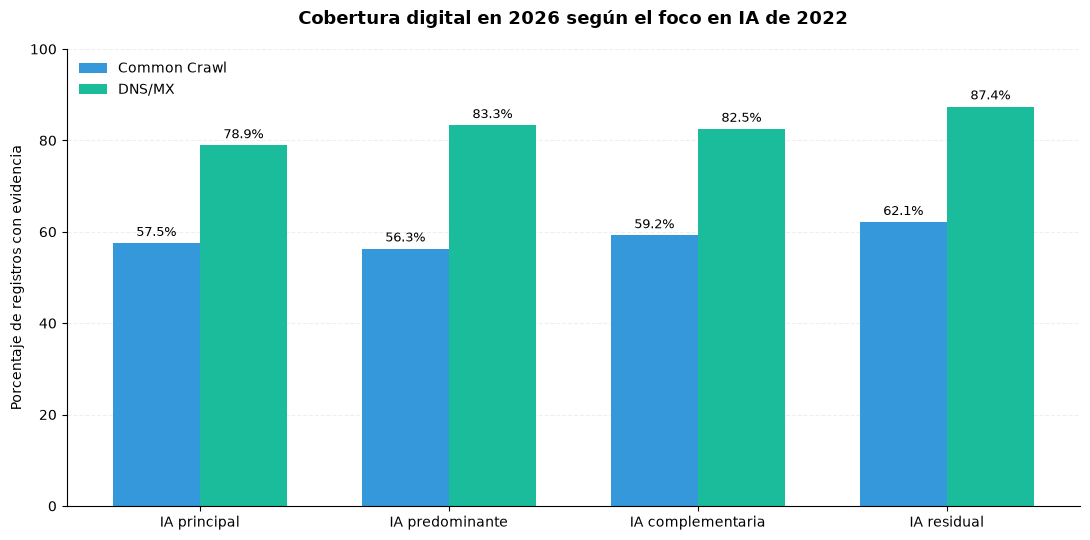

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# ═══════════════════════════════════════════════════════════
# Gráfico: Cobertura según Foco en IA
# ═══════════════════════════════════════════════════════════

x = np.arange(len(segmentos_ia))
ancho = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))

# Barras para Common Crawl
barras_cc = ax.bar(
    x - ancho/2,
    segmentos_ia['Common Crawl (%)'],
    ancho,
    label='Common Crawl',
    color='#3498db'
)

# Barras para DNS/MX
barras_mx = ax.bar(
    x + ancho/2,
    segmentos_ia['DNS/MX (%)'],
    ancho,
    label='DNS/MX',
    color='#1abc9c'
)

# Etiquetas de datos
for barras in [barras_cc, barras_mx]:
    ax.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=9)

# Configuración de ejes
ax.set_xticks(x)
ax.set_xticklabels([
    'IA principal',
    'IA predominante',
    'IA complementaria',
    'IA residual'
])

ax.set_ylim(0, 100)
ax.set_ylabel('Porcentaje de registros con evidencia')
ax.set_title(
    'Cobertura digital en 2026 según el foco en IA de 2022',
    fontsize=13,
    fontweight='bold',
    pad=18
)

# Estética
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 8.1. La interpretación de la paradoja

El gráfico revela una paradoja sorprendente:

- Las **AI Service residual** (las que menos IA ofrecían en 2022) tienen la **cobertura web más alta (62.1%)** y la **cobertura de correo más alta (87.4%)**.
- Las **AI Focus principal** (las más especializadas) tienen la **cobertura más baja**: 57.5% en web y 78.9% en correo.

**¿Qué significa esto?**
No significa que las empresas "AI First" hayan desaparecido. Significa que **el ecosistema de IA no es homogéneo**:

- Las empresas con foco residual suelen ser consultoras o agencias de software más grandes, con estructuras web más consolidadas.
- Las "AI Focus" pueden ser startups o laboratorios más pequeños, con sitios de una sola página, detrás de firewalls, o que simplemente bloquean a los bots.

**La lección metodológica:** No podemos asumir que "más IA = más presencia web". La cobertura técnica está mediada por el tamaño de la empresa y su infraestructura, no solo por su especialización.

### 8.2. ¿Qué encontramos al comparar los segmentos de IA?

Al relacionar el foco en inteligencia artificial declarado en 2022 con las señales digitales recuperadas en 2026, encontramos diferencias entre los cuatro segmentos.

Las empresas con **IA residual (0–19%)** presentan los porcentajes más altos de evidencia en ambas fuentes: 62,1% en Common Crawl y 87,4% en DNS/MX.

En cambio, las empresas con **IA principal (70–100%)** registran 57,5% en Common Crawl y 78,9% en DNS/MX.

Esto muestra que una mayor especialización declarada en IA en 2022 no se traduce necesariamente en una mayor presencia de estas señales digitales en 2026.

Sin embargo, los resultados no permiten explicar las causas de esas diferencias ni establecer relaciones con la continuidad operativa de las empresas.

**El foco en IA es una característica útil para segmentar el universo original, pero no constituye por sí mismo un indicador de permanencia o actividad empresarial.**

*Nota metodológica: comparación descriptiva sobre 3.096 registros originales de 2022. Los porcentajes corresponden a cada fuente por separado y no representan la cobertura acumulada de evidencia digital.*

## 9. El análisis geográfico: ¿Dónde están las empresas que rescatamos?

Hasta ahora analizamos la evidencia por segmento de IA. Pero la geografía es una dimensión fundamental del ecosistema. En esta sección, exploramos cómo varía la evidencia digital según la región y el país.

En el capítulo anterior analizamos cómo distintas fuentes permitieron ampliar la evidencia digital recuperada sobre los 3.094 dominios únicos del dataset original.

Pero las empresas registradas en 2022 no formaban un grupo homogéneo. Pertenecían a distintos países y regiones

Esto abre una nueva pregunta:

> **¿Encontramos diferencias en la evidencia digital de 2026 según el país, la región  que tenían las empresas en 2022?**

Para explorarlo, retomamos las características del dataset original y las relacionamos con los resultados de evidencia digital obtenidos en 2026.

### 9.1. La cobertura por región

Primero, observamos la cobertura individual de cada fuente por región. La tabla muestra la cantidad de registros y el porcentaje de cobertura de Common Crawl y DNS/MX.

In [20]:
import pandas as pd

# Agregados regionales del Notebook Unificado
regiones = pd.DataFrame({
    'Región': [
        'Norteamérica', 'Europa', 'Asia', 'Sudamérica',
        'Oceanía', 'Medio Oriente', 'África', 'Centroamérica'
    ],
    'Registros': [1074, 921, 755, 141, 100, 58, 25, 22],
    'Common Crawl (%)': [59.0, 61.9, 59.2, 61.7, 48.0, 60.3, 44.0, 59.1],
    'DNS/MX (%)': [85.9, 84.0, 81.3, 85.1, 78.0, 81.0, 76.0, 81.8]
})

assert regiones['Registros'].sum() == 3096

print("✅ Validación exitosa: Los registros suman 3.096.")
display(regiones)

✅ Validación exitosa: Los registros suman 3.096.


,Región,Registros,Common Crawl (%),DNS/MX (%)
0,Norteamérica,1074,59.0,85.9
1,Europa,921,61.9,84.0
2,Asia,755,59.2,81.3
3,Sudamérica,141,61.7,85.1
4,Oceanía,100,48.0,78.0
5,Medio Oriente,58,60.3,81.0
6,África,25,44.0,76.0
7,Centroamérica,22,59.1,81.8


> **Nota metodológica:** La tabla suma 3.096 registros, mientras que el análisis se realiza sobre **3.094 dominios únicos**. La diferencia de 2 registros se debe a que dos empresas del dataset original comparten el mismo dominio. Para el análisis de evidencia digital, se contabilizó cada dominio una sola vez.

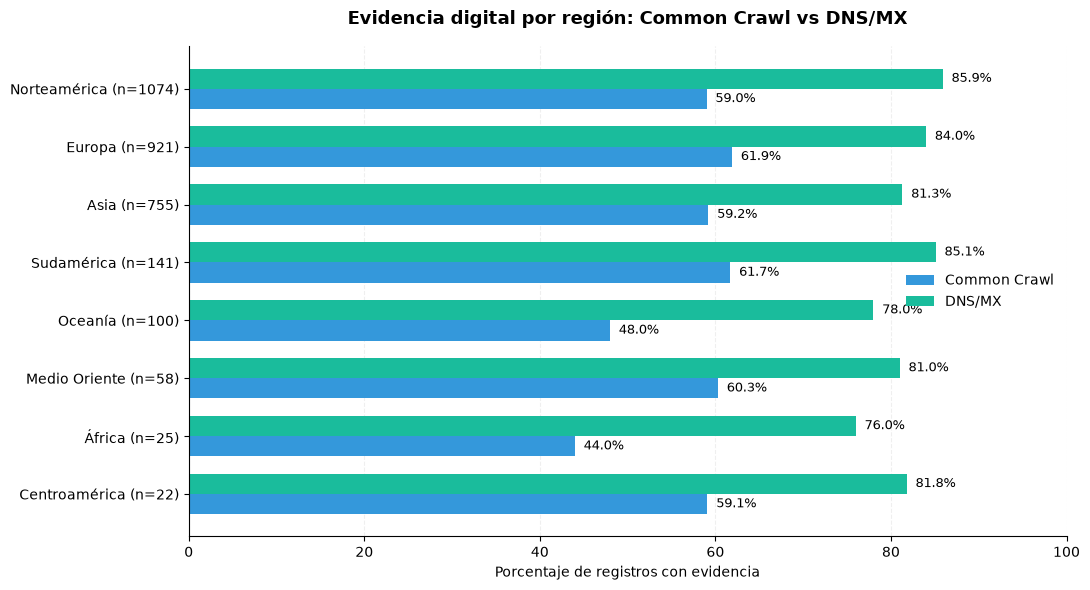

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Gráfico de barras horizontales agrupadas
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(regiones))
alto = 0.35

barras_cc = ax.barh(y + alto/2, regiones['Common Crawl (%)'], height=alto, label='Common Crawl', color='#3498db')
barras_mx = ax.barh(y - alto/2, regiones['DNS/MX (%)'], height=alto, label='DNS/MX', color='#1abc9c')

for barras in [barras_cc, barras_mx]:
    for barra in barras:
        valor = barra.get_width()
        ax.text(valor + 1, barra.get_y() + barra.get_height()/2, f'{valor:.1f}%', va='center', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels([f"{region} (n={n})" for region, n in zip(regiones['Región'], regiones['Registros'])])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Porcentaje de registros con evidencia')
ax.set_title('Evidencia digital por región: Common Crawl vs DNS/MX', fontsize=13, fontweight='bold', pad=16)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 9.2. La interpretación regional

El gráfico revela un patrón claro: **en todas las regiones, la cobertura de DNS/MX es notablemente superior a la de Common Crawl**. 

- **Norteamérica y Europa** tienen la mayor cantidad de registros y una cobertura de correo superior al 84%.
- **Oceanía y África** muestran una caída más pronunciada en la evidencia web (por debajo del 50%), aunque el correo se mantiene por encima del 76%.
- **La brecha entre fuentes** es transversal: en todos los continentes, el DNS "ve" más que el crawler.

**Conclusión:** La evidencia digital no es homogénea geográficamente. Pero el hecho de que el DNS mantenga una cobertura estable en todas las regiones sugiere que **la infraestructura técnica es más democrática que la captura web**, que está sesgada por la accesibilidad de los sitios a los bots.

### 9.3. La distribución de evidencia cruzada por región

El gráfico anterior mostró la cobertura individual de cada fuente. Pero para entender realmente cómo se combinan, necesitamos ver la **distribución de las 4 categorías de evidencia** (`Ambas`, `Solo Web`, `Solo MX`, `Ninguna`) dentro de cada región.

Esto nos permite responder: ¿qué proporción de cada región tiene ambas señales? ¿Cuánta tiene solo una? ¿Y cuánta no tiene ninguna?

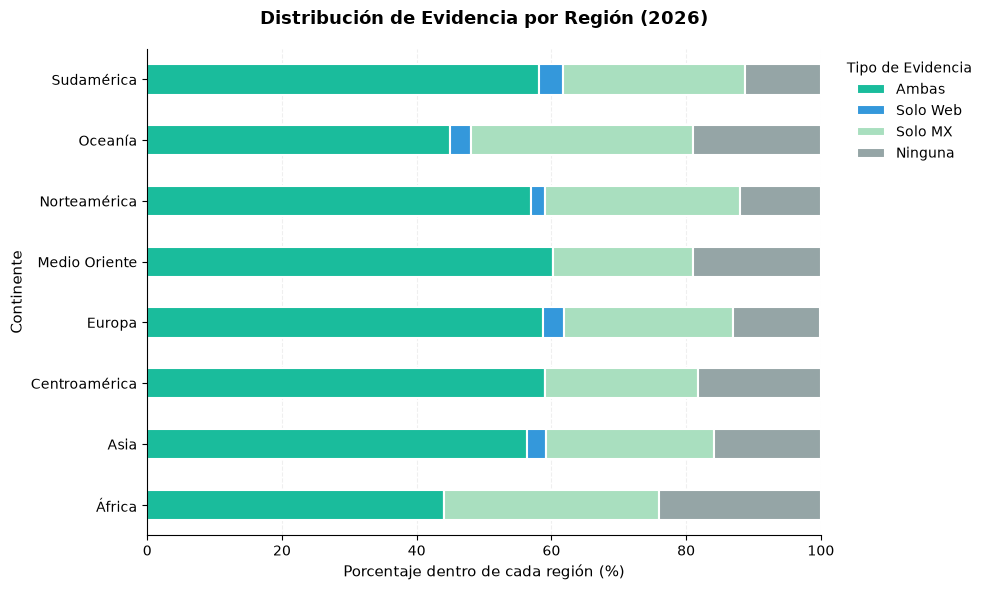

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# ═══════════════════════════════════════════════════════════
# Gráfico: Distribución de las 4 categorías por región (Estilizado)
# ═══════════════════════════════════════════════════════════

region_data = [
    {'Región': 'África', 'Ambas': 44.0, 'Solo Web': 0.0, 'Solo MX': 32.0, 'Ninguna': 24.0},
    {'Región': 'Asia', 'Ambas': 56.4, 'Solo Web': 2.8, 'Solo MX': 24.9, 'Ninguna': 15.9},
    {'Región': 'Centroamérica', 'Ambas': 59.1, 'Solo Web': 0.0, 'Solo MX': 22.7, 'Ninguna': 18.2},
    {'Región': 'Europa', 'Ambas': 58.8, 'Solo Web': 3.0, 'Solo MX': 25.2, 'Ninguna': 12.9},
    {'Región': 'Medio Oriente', 'Ambas': 60.3, 'Solo Web': 0.0, 'Solo MX': 20.7, 'Ninguna': 19.0},
    {'Región': 'Norteamérica', 'Ambas': 57.0, 'Solo Web': 2.0, 'Solo MX': 29.0, 'Ninguna': 12.0},
    {'Región': 'Oceanía', 'Ambas': 45.0, 'Solo Web': 3.0, 'Solo MX': 33.0, 'Ninguna': 19.0},
    {'Región': 'Sudamérica', 'Ambas': 58.2, 'Solo Web': 3.5, 'Solo MX': 27.0, 'Ninguna': 11.3}
]

df_region = pd.DataFrame(region_data).set_index('Región')

# Colores de la paleta
colores = ['#1abc9c', '#3498db', '#a9dfbf', '#95a5a6']

fig, ax = plt.subplots(figsize=(10, 6))

# Barras apiladas con estilo limpio
df_region.plot(
    kind='barh', 
    stacked=True, 
    color=colores, 
    edgecolor='white', # Borde blanco para separar las categorías sutilmente
    linewidth=1.5,
    ax=ax
)

# Títulos y etiquetas
ax.set_title('Distribución de Evidencia por Región (2026)', fontsize=13, fontweight='bold', pad=18)
ax.set_xlabel('Porcentaje dentro de cada región (%)', fontsize=11)
ax.set_ylabel('Continente', fontsize=11)

# Estética (igual a tus otros gráficos)
ax.set_xlim(0, 100)
ax.legend(title='Tipo de Evidencia', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.2) # Grid suave
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path
import pandas as pd
import plotly.express as px
import os

# --------------------------------------------------
# 1. CARGAR RESULTADOS GEOGRÁFICOS AGREGADOS
# --------------------------------------------------

# Usamos un try/except para que funcione tanto local como en GitHub
ruta = "evidencia_geografica_2026.csv"

if os.path.exists(ruta):
    print(f"📂 Cargando desde archivo local: {ruta}")
    mapa_paises = pd.read_csv(ruta, encoding="utf-8-sig")
else:
    # Ruta de GitHub para cuando se suba el repo
    url_github = "https://raw.githubusercontent.com/mastro75/ai-companies-2026/main/data/evidencia_geografica_2026.csv"
    print(f"🌐 Cargando desde GitHub: {url_github}")
    mapa_paises = pd.read_csv(url_github)

# Validación de resultados
assert len(mapa_paises) == 89, "Revisar cantidad de países"
assert mapa_paises["coincidencias"].sum() == 2252, "Revisar coincidencias"

print("✅ CSV cargado correctamente")
print("Países:", len(mapa_paises))
print("Coincidencias:", mapa_paises["coincidencias"].sum())

# --------------------------------------------------
# 2. CREAR MAPAMUNDI
# --------------------------------------------------

fig = px.choropleth(
    mapa_paises,
    locations="iso_code",
    locationmode="ISO-3",
    color="porcentaje",
    hover_name="Pais",
    hover_data={
        "iso_code": False,
        "dominios": True,
        "coincidencias": True,
        "porcentaje": ":.1f"
    },
    # Escala personalizada: Amarillo → Verde → Azul
    color_continuous_scale=[
        [0.0, '#F9E79F'],  # Amarillo suave
        [0.5, '#7DCEA0'],  # Verde medio
        [1.0, '#1F618D']   # Azul oscuro
    ],
    range_color=[0, 100],
    labels={
        "porcentaje": "Coincidencia (%)",
        "dominios": "Dominios analizados",
        "coincidencias": "Título válido + MX"
    }
)

# --------------------------------------------------
# 3. ESTILO GEOGRÁFICO
# --------------------------------------------------

fig.update_traces(
    marker_line_color="#FFFFFF",
    marker_line_width=0.35
)

fig.update_geos(
    projection_type="equirectangular",
    showland=True,
    landcolor="#E4E9F0",
    showcountries=True,
    countrycolor="#FFFFFF",
    countrywidth=0.35,
    showcoastlines=False,
    showframe=False,
    showocean=True,
    oceancolor="#F8FAFC",
    bgcolor="#F8FAFC",
    # Con equirectangular y estos rangos, el mapa se ve completo
    lataxis_range=[-60, 85],
    lonaxis_range=[-180, 180]
)

# --------------------------------------------------
# 4. TÍTULO, LEYENDA Y DISEÑO
# --------------------------------------------------

fig.update_layout(
    title=dict(
        text=(
            "<b>AI Companies 2 — Exploring Digital Evidence in 2026</b>"
            "<br><span style='font-size:16px;color:#64748B'>"
            "Coincidencia de título HTML válido y MX por país"
            "</span>"
        ),
        x=0.04,
        xanchor="left",
        y=0.96,
        font=dict(
            family="Arial",
            size=22,
            color="#172B4D"
        )
    ),
    paper_bgcolor="#F8FAFC",
    geo_bgcolor="#F8FAFC",
    font=dict(
        family="Arial",
        size=13,
        color="#334155"
    ),
    height=650,
    margin=dict(
        l=20,
        r=20,
        t=115,
        b=100
    ),
    coloraxis_colorbar=dict(
        title=dict(
            text="Coincidencia de señales (%)",
            side="top",
            font=dict(size=12)
        ),
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.10,
        len=0.55,
        thickness=12,
        tickvals=[0, 20, 40, 60, 80, 100],
        ticksuffix="%",
        outlinewidth=0
    )
)

# --------------------------------------------------
# 5. GUARDAR Y MOSTRAR
# --------------------------------------------------
fig.write_html('mapa_coincidencia_2026.html')
print("✅ Mapa guardado como 'mapa_coincidencia_2026.html'")
fig.show(renderer="browser")

📂 Cargando desde archivo local: evidencia_geografica_2026.csv
✅ CSV cargado correctamente
Países: 89
Coincidencias: 2252
✅ Mapa guardado como 'mapa_coincidencia_2026.html'


### 9.4. ¿Qué encontramos al comparar países?

Al analizar los diez países con mayor cantidad de registros en 2022, observamos que DNS/MX presenta porcentajes de cobertura superiores a Common Crawl en todos los casos.

Sin embargo, la diferencia entre ambas fuentes varía considerablemente.

- **Pakistán (32,8 puntos porcentuales), Australia (31,3 pp) y Canadá (31,0 pp)** presentan las mayores brechas.
- **Ucrania (13,1 pp)** presenta la menor diferencia entre ambas fuentes.
- Estados Unidos, el país con mayor cantidad de registros del dataset, presenta una brecha de 26,2 puntos porcentuales.

Esto muestra que la evidencia digital recuperada no se distribuye de manera uniforme entre países y que los resultados pueden variar significativamente según la fuente consultada.

Al ampliar el análisis mediante el mapa geográfico, observamos también diferencias en la proporción de dominios que presentan simultáneamente un título HTML válido y evidencia DNS/MX.

Esta segunda visualización incorpora los 89 países de la muestra y permite explorar la distribución de ambas señales más allá de los diez países con mayor representación.

**La brecha entre fuentes no representa necesariamente evidencia adicional exclusiva:** un mismo dominio puede aparecer en ambas. Del mismo modo, la coincidencia de título válido y MX indica evidencia digital observable, pero no confirma que la empresa continúe operando.

### 9.5. ¿Qué aprendimos al relacionar la evidencia con el perfil de las empresas?

En este capítulo incorporamos una nueva dimensión al análisis: las características de las empresas registradas en 2022.

Al comparar regiones, países y niveles de especialización en IA, encontramos diferencias en la cobertura de las señales digitales recuperadas en 2026.

Dos observaciones resultan especialmente interesantes:

**1. La evidencia digital presenta diferencias geográficas.**

Las tasas de cobertura varían entre regiones y países. La comparación entre Common Crawl y DNS/MX muestra que la magnitud de esas diferencias depende de la fuente utilizada.

El mapa de coincidencia entre título HTML válido y MX agrega otra perspectiva: permite observar cómo varía la presencia simultánea de ambas señales entre los países representados en la muestra.

Estas diferencias pueden estar relacionadas con factores técnicos, características de los dominios y la composición de la muestra. No permiten, por sí solas, concluir que las empresas de determinados países tengan una mayor tasa de continuidad operativa.

**2. La especialización en IA permite explorar diferencias entre perfiles de empresas.**

La segmentación original de 2022 permite comparar la evidencia digital de empresas con distintos niveles de especialización en IA.

Este análisis aporta contexto para interpretar los resultados, pero no establece una relación causal entre la especialización de una empresa y la evidencia digital observada cuatro años después.

## 10. Galería visual: los casos detrás de las señales

Los números agregados nos dicen *qué* pasó, pero a veces los casos individuales nos muestran *cómo* pasó. 

A continuación, compartimos una selección de capturas de pantalla que ilustran los distintos estados de la evidencia digital que encontramos al rastrear los dominios. 

*Nota metodológica: para proteger la identidad de las empresas, hemos difuminado los dominios en estas capturas. El fenómeno es real, pero el foco está en el tipo de señal, no en la empresa específica.*

### Figura 1: El "Todo Bien" (Web activa y Correo activo)

**Señal:** `FOUND` (Common Crawl) + `MX_FOUND` (DNS).
**Qué ilustra:** El caso base. Una empresa que mantuvo tanto su sitio web funcional como su infraestructura de correo a lo largo de los años. Es el estado que esperaríamos encontrar en empresas que siguen operando normalmente.

![Figura 1: Web activa](images/fig1_web_activa.png)

### Figura 2: El "Solo MX" (Sin web, pero con correo activo)

**Señal:** `NO_CAPTURE` (Common Crawl) + `MX_FOUND` (DNS).
**Qué ilustra:** La primera prueba de la triangulación. Si solo hubiéramos mirado Common Crawl, habríamos asumido que este dominio estaba muerto. Sin embargo, el DNS nos muestra que la infraestructura de correo sigue configurada y activa. La empresa puede haber cambiado su página web o estar usando el dominio solo para comunicaciones internas.

![Figura 2: Sin web pero con correo](images/fig2_solo_mx.png)

### Figura 3: El Abandono Comercial (Dominio en venta)

**Señal:** `NO_CAPTURE` (Common Crawl) + `title_interpretacion` = "Dominio en venta".
**Qué ilustra:** El ciclo de vida del activo digital. La empresa original dejó de usar el dominio, y este fue a parar a un servicio de parking o venta (como GoDaddy). El sitio web "existe", pero ya no representa a la empresa de 2022. Además, los bots suelen ser bloqueados en estas plataformas, lo que genera un `NO_CAPTURE` técnico.

![Figura 3: Dominio en venta](images/fig3_dominio_venta.png)

### Figura 4: El Error Técnico (DNS roto o configuración fallida)

**Señal:** `UNKNOWN` (DNS) o `NO_CAPTURE` por error de resolución.
**Qué ilustra:** Un dominio que existe y tiene un proveedor de infraestructura (como Cloudflare), pero que falla al resolver o tiene una mala configuración. Demuestra que el `NO_CAPTURE` no siempre significa que el dominio esté "muerto" o en venta; a veces es simplemente un problema técnico de configuración que impide que los bots y los usuarios accedan a él.

![Figura 4: Error de DNS](images/fig4_error_dns.png)

### Figura 5: El Misterio de UNKNOWN (El fantasma del DNS)

**Señal:** `UNKNOWN` (DNS) + `SIN_DNS` (web_status).
**Qué ilustra:** La bolsa de incertidumbre. Al consultar el DNS de este dominio, no obtuvimos un registro MX claro, pero tampoco un error de que no exista. Podría ser un firewall corporativo que bloquea las consultas, un dominio con TTL expirado, o simplemente un sitio caído. Es el tipo de caso que la versión actual del análisis no puede resolver, y que queda como pregunta abierta para futuras investigaciones.

![Figura 5: El fantasma del DNS](images/fig5_unknown.png)

### ¿Qué nos dicen estas capturas?

Al poner estas 5 imágenes juntas, el mensaje es claro: **la "ausencia de evidencia" no es un concepto monolítico**. 

Detrás de un `NO_CAPTURE` o un `UNKNOWN` hay un abanico de situaciones: desde empresas operando normalmente con firewalls estrictos, hasta dominios abandonados que esperan un comprador. 

Cruzar Common Crawl con DNS/MX nos permitió separar algunas de estas situaciones (por ejemplo, identificando las que seguían teniendo correo). Para el resto, la respuesta visual nos invita a seguir investigando.

 ## 11. Conclusiones: de señales aisladas a evidencia relacionada

Esta investigación comenzó con una pregunta: **¿qué evidencia digital podemos encontrar en 2026 sobre los dominios de empresas de inteligencia artificial registradas en 2022?**

Partimos de 3.094 dominios únicos y exploramos distintas fuentes para comprender qué información podíamos recuperar.

El recorrido nos dejó tres aprendizajes principales.

**1. Una fuente no alcanza para comprender todo el universo.**

Common Crawl permitió identificar capturas para 1.844 dominios (59,6%). Al incorporar HTML Title y DNS/MX, la cobertura acumulada alcanzó 2.771 dominios (89,6%).

Esto representa **927 dominios adicionales** con evidencia digital identificada mediante fuentes complementarias.

**2. Relacionar señales aporta más información que analizarlas por separado.**

Los cruces realizados con SQLite y SQL permitieron identificar dominios sin capturas en Common Crawl que sí presentaban títulos HTML o registros MX.

También permitieron distinguir diferentes resultados técnicos, como errores de acceso, ausencia de títulos recuperables y falta de resolución DNS.

**3. El perfil de las empresas abre nuevas preguntas.**

Al relacionar la evidencia con las características registradas en 2022, encontramos diferencias entre regiones, países y niveles de especialización en IA.

Sin embargo, estas diferencias no permiten establecer relaciones causales ni determinar qué empresas continúan operando.

### El aprendizaje principal

**El hallazgo no es cuántas empresas sobrevivieron desde 2022, sino cuánta evidencia digital pudimos recuperar en 2026 y qué aprendimos al relacionarla.**

La investigación comenzó buscando información sobre empresas y terminó mostrando algo igualmente valioso: **cómo distintas fuentes pueden ampliar nuestra capacidad de observar un problema, sin eliminar completamente la incertidumbre.**

## 12. Límites, ética y próximos pasos

Este análisis permitió ampliar la evidencia digital disponible sobre los dominios de 2022, pero también dejó en claro cuáles son sus propios límites.

A continuación, resumimos lo que **no** podemos concluir, la decisión ética que tomamos respecto a los datos y las preguntas que quedan abiertas para una próxima etapa.

### 12.1. Lo que este análisis no puede concluir

A lo largo del notebook insistimos en una distinción fundamental: **observar evidencia digital no es medir la supervivencia empresarial**. 

Por eso, este trabajo **no permite**:

- El dataset representa un conjunto específico de empresas registradas en Clutch.co en 2022 a partir del dataset publicado en Kaggle (agregar fuente), no a todas las empresas de inteligencia artificial del mundo.
- **Determinar si una empresa continúa operando.** Que un dominio no tenga web (`NO_CAPTURE`) no significa que la empresa haya quebrado. Puede haber cambiado de dominio, haber sido adquirida, o simplemente estar bloqueando a los bots.
- A su vez, la evidencia digital asociada a un dominio no permite confirmar que la misma empresa continúe operando en 2026, ni establecer continuidad jurídica, facturación o cantidad de empleados.
- La ausencia de capturas en Common Crawl no implica ausencia de actividad digital. Los errores de acceso y la falta de resolución DNS deben interpretarse como resultados técnicos diferente.
- Los registros MX indican configuración DNS para correo electrónico, pero no verifican su uso efectivo.
- **Afirmar que un título HTML válido pertenece a la misma empresa de 2022.** El dominio pudo haber sido vendido, alquilado o reutilizado por otra organización.
- **Establecer relaciones causales.** Que las empresas con menor foco en IA tengan mayor cobertura web no significa que la especialización en IA cause una desaparición digital. Hay factores de tamaño, presupuesto y estrategia que este dataset no captura.
- **Generalizar al universo total de empresas de IA.** Analizamos un dataset específico de Kaggle en base a Clutch.co (2022). No representa a todo el mercado global de inteligencia artificial hoy a 2026.
- **Medir la calidad o la transparencia de las empresas.** La presencia de una web con título no indica que la empresa sea más o menos transparente en sus prácticas comerciales.

### 12.2. La ética de datos y la anonimización

Una de las decisiones más importantes de este proyecto fue **priorizar la privacidad de las empresas sobre la exposición de los datos individuales**.

Aunque el dataset original de 2022 es público, cruzar esos datos con señales técnicas de 2026 (como el estado del dominio o si está en venta) no lo realizamos para no vincular directamente con los nombres de empresas.

Para evitarlo, aplicamos un proceso de **anonimización por diseño**:
- Todos los datos públicos utilizan un **`ID_Interno`** en lugar del dominio o el nombre de la empresa.
- La relación entre el `ID_Interno` y la empresa real solo existe en el dataset local privado.
- Las señales técnicas y la geografía se mantienen para permitir el análisis de patrones agregados.

Este enfoque nos permite compartir la metodología y los hallazgos sin exponer a ninguna empresa específica. Creemos que **la ética de datos es parte fundamental del análisis**, no un agregado posterior.

### 12.3. Conclusión final

Este proyecto comenzó intentando entender qué había ocurrido con las empresas de IA registradas en 2022.

El primer acercamiento fue buscar evidencia sobre las empresas como entidades jurídicas. Pero los resultados fueron limitados y llevaron a cambiar el enfoque: **pasar de los nombres de empresas a los dominios web registrados en 2022**.

Ese cambio también modificó lo que podíamos investigar. Ya no se trataba de determinar qué empresas seguían operando, sino de explorar qué evidencia digital podíamos encontrar sobre sus dominios en 2026.

Common Crawl permitió identificar capturas para el **59,6% de los dominios**. Al incorporar HTML Title y DNS/MX, la cobertura alcanzó el **89,6%**.

La respuesta no fue un número de empresas que sobrevivieron, sino un panorama más completo de **evidencia digital, sesgos de fuentes y límites metodológicos**, construido a partir de la triangulación de Common Crawl, DNS/MX, HTML Title y `web_status`.

**El principal aprendizaje fue que no encontrar evidencia en una fuente no significa que no exista. Y encontrarla tampoco significa necesariamente lo que creemos.**
